In [3]:
!pip install yfinance pandas_ta matplotlib numpy pandas ccxt

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 136.3/136.3 kB 8.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.3/6.3 MB 93.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.6/1.6 MB 65.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 641.1/641.1 kB 37.3 MB/s eta 0:00:00


In [4]:
import ccxt
import pandas as pd
from datetime import datetime

def fetch_full_history(symbol='BTC/USDT', timeframe='1h', start_date='2020-01-01 00:00:00'):
    # 1. Khởi tạo sàn Binance
    exchange = ccxt.binance()

    # 2. Chuyển đổi ngày bắt đầu sang timestamp (ms)
    since = exchange.parse8601(start_date)

    all_candles = []
    print(f"⏳ Đang tải {symbol} khung {timeframe} từ {start_date}...")

    while True:
        try:
            # Lấy 1000 nến mỗi lần (Limit tối đa của Binance)
            candles = exchange.fetch_ohlcv(symbol, timeframe, since, limit=1000)

            if not candles:
                break

            # Cập nhật thời gian cho lần gọi tiếp theo (Thời gian nến cuối + 1 khoảng timeframe)
            # Timeframe '1h' = 3600000 ms
            since = candles[-1][0] + 3600000
            all_candles += candles

            # In tiến độ
            current_date = datetime.fromtimestamp(candles[-1][0] / 1000)
            print(f"   -> Đã tải đến: {current_date}")

            # Nếu đã tải đến sát hiện tại thì dừng
            if candles[-1][0] > exchange.milliseconds() - 3600000:
                break

        except Exception as e:
            print(f"Lỗi kết nối: {e}")
            break

    # 3. Chuyển sang DataFrame
    df = pd.DataFrame(all_candles, columns=['Timestamp', 'Open', 'High', 'Low', 'Close', 'Volume'])
    df['Date'] = pd.to_datetime(df['Timestamp'], unit='ms')
    df.set_index('Date', inplace=True)

    # Xóa cột Timestamp thừa
    df.drop(columns=['Timestamp'], inplace=True)

    return df

# --- CHẠY HÀM ---
# Bạn có thể đổi thành ETH/USDT, BNB/USDT...
df_crypto = fetch_full_history('BTC/USDT', timeframe='1h', start_date='2020-01-01 00:00:00')

# Lưu ra file CSV để dùng cho Backtest
file_name = 'BTC_USDT_1H_Full.csv'
df_crypto.to_csv(file_name)
print(f"✅ Đã lưu file {file_name} ({len(df_crypto)} nến)")

⏳ Đang tải BTC/USDT khung 1h từ 2020-01-01 00:00:00...
Lỗi kết nối: binance GET https://api.binance.com/api/v3/exchangeInfo 451  {
  "code": 0,
  "msg": "Service unavailable from a restricted location according to 'b. Eligibility' in https://www.binance.com/en/terms. Please contact customer service if you believe you received this message in error."
}
✅ Đã lưu file BTC_USDT_1H_Full.csv (0 nến)


📥 Đang tải dữ liệu BTC-USD khung 1h từ Yahoo Finance...


/tmp/ipython-input-637782377.py:30: FutureWarning: YF.download() has changed argument auto_adjust default to True
  df = yf.download(TICKER, period="730d", interval="1h", progress=False)


✅ Dữ liệu đã tải: 17471 nến (Từ 2024-01-09 00:00:00+00:00 đến 2026-01-07 06:00:00+00:00)
⏳ Đang chạy Backtest...

KẾT QUẢ CHIẾN LƯỢC: BTC-USD (1H)
----------------------------------------
Vốn ban đầu:      $10,000.00
Vốn cuối cùng:    $20,147.35
Lợi nhuận ròng:   $10,147.35 (101.47%)
----------------------------------------
Max Drawdown:     -7.40%
Sharpe Ratio:     2.33
Tổng số lệnh:     198


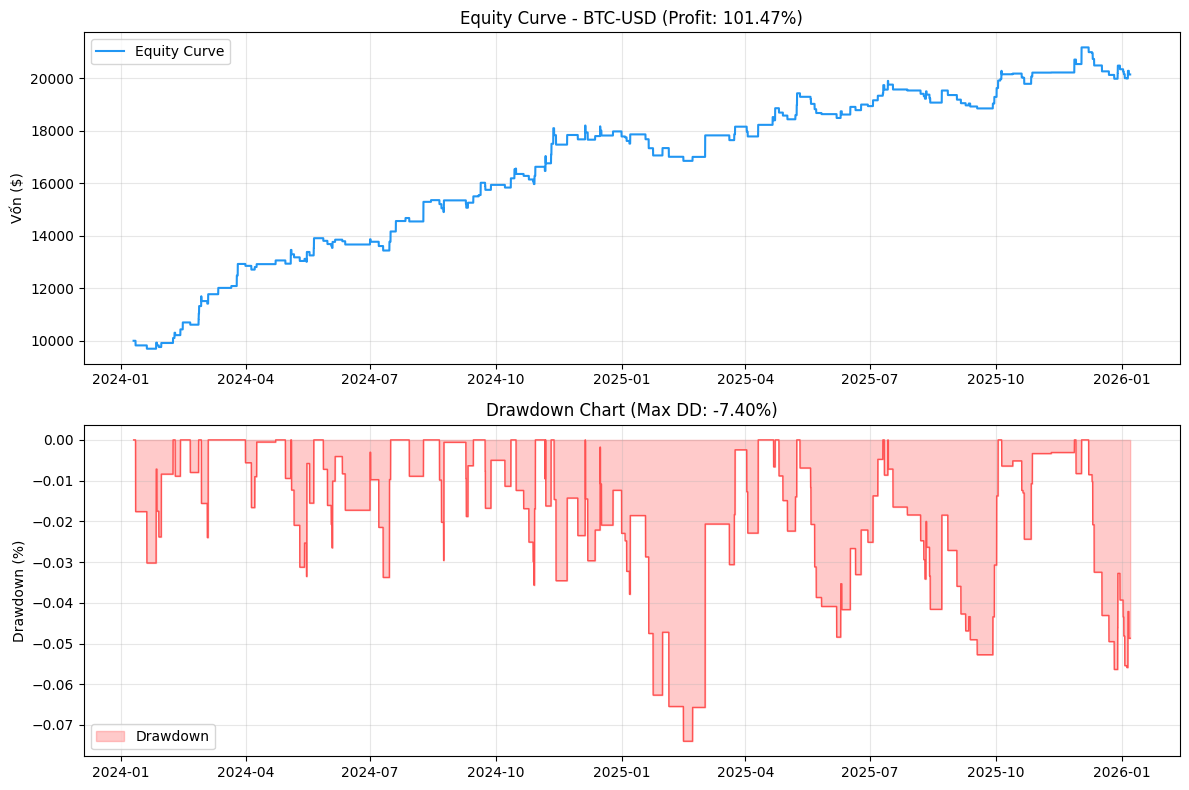


📊 Phân bổ lý do thoát lệnh (Exit Reasons):
Reason
SL Hit       100
TP Hit        55
Time Exit     43
Name: count, dtype: int64


In [5]:
import yfinance as yf
import pandas as pd
import pandas_ta as ta
import numpy as np
import matplotlib.pyplot as plt

# ==========================================
# 1. CẤU HÌNH THAM SỐ (STRATEGY PARAMETERS)
# ==========================================
TICKER = 'BTC-USD'
TIMEFRAME = '1h'
INITIAL_CAPITAL = 10000

# Strategy Params
ATR_RISING_PERIOD = 30  # Chu kỳ xét đà tăng ATR
ATR_ENTRY_PERIOD = 20   # Chu kỳ ATR dùng để tính khoảng cách Entry
ATR_TP_PERIOD = 25      # Chu kỳ ATR dùng để tính TP
LOOKBACK = 20           # Số nến tìm đỉnh đáy cũ
ENTRY_FACTOR = 2.4      # Entry = High/Low +/- (Factor * ATR)
SL_FACTOR = 1.6
TP_FACTOR = 4.4
TIME_EXIT_BARS = 18     # Thoát sau 18 tiếng
ORDER_EXPIRY_BARS = 8   # Hủy lệnh chờ sau 8 tiếng

# ==========================================
# 2. TẢI DỮ LIỆU BTC-USD 1H
# ==========================================
print(f"📥 Đang tải dữ liệu {TICKER} khung {TIMEFRAME} từ Yahoo Finance...")
# Yahoo Finance giới hạn data 1h trong 730 ngày gần nhất (khoảng 2 năm)
df = yf.download(TICKER, period="730d", interval="1h", progress=False)

# Xử lý MultiIndex nếu có (Fix lỗi phiên bản mới của yfinance)
if isinstance(df.columns, pd.MultiIndex):
    df.columns = df.columns.get_level_values(0)

df.dropna(inplace=True)
print(f"✅ Dữ liệu đã tải: {len(df)} nến (Từ {df.index[0]} đến {df.index[-1]})")

# ==========================================
# 3. TÍNH TOÁN CHỈ BÁO (INDICATORS)
# ==========================================
# Tính ATR
df['ATR30'] = ta.atr(df['High'], df['Low'], df['Close'], length=ATR_RISING_PERIOD)
df['ATR20'] = ta.atr(df['High'], df['Low'], df['Close'], length=ATR_ENTRY_PERIOD)
df['ATR25'] = ta.atr(df['High'], df['Low'], df['Close'], length=ATR_TP_PERIOD)

# Tính Rolling Max High / Min Low cho điểm neo entry
df['HighestClose'] = df['Close'].rolling(window=LOOKBACK).max()
df['LowestClose'] = df['Close'].rolling(window=LOOKBACK).min()

df.dropna(inplace=True)

# ==========================================
# 4. BACKTEST ENGINE (EVENT-DRIVEN)
# ==========================================
def run_backtest_engine(data):
    capital = INITIAL_CAPITAL
    position = 0 # 0: Cash, 1: Long, -1: Short
    entry_price = 0
    sl_price = 0
    tp_price = 0
    bars_held = 0

    # Quản lý lệnh chờ (Pending Orders)
    pending_long = None  # Tuple: (Price, TimeIndex)
    pending_short = None

    equity_curve = [capital] * 4 # Padding cho những nến đầu
    trades = []

    # Convert sang numpy array để loop nhanh hơn
    closes = data['Close'].values
    highs = data['High'].values
    lows = data['Low'].values
    times = data.index

    # Indicator arrays
    atr30 = data['ATR30'].values
    atr20 = data['ATR20'].values
    atr25 = data['ATR25'].values
    h_close = data['HighestClose'].values
    l_close = data['LowestClose'].values

    # Bắt đầu vòng lặp (Start loop)
    # Start at index 4 to allow looking back safely
    for i in range(4, len(data)):
        current_time = times[i]
        current_price = closes[i]
        current_high = highs[i]
        current_low = lows[i]

        # --- A. XỬ LÝ LỆNH ĐANG CHẠY (ACTIVE POSITION) ---
        if position != 0:
            bars_held += 1
            exit_signal = False
            reason = ""
            pnl_amount = 0

            # 1. Check SL/TP
            if position == 1: # Đang Long
                if current_low <= sl_price:
                    exit_signal = True; reason = "SL Hit"
                    exit_price = sl_price
                elif current_high >= tp_price:
                    exit_signal = True; reason = "TP Hit"
                    exit_price = tp_price
                # Time Exit (Nếu chưa chạm SL/TP)
                elif bars_held >= TIME_EXIT_BARS:
                    exit_signal = True; reason = "Time Exit"
                    exit_price = current_price # Close at market

                if exit_signal:
                    pnl_amount = (exit_price - entry_price) / entry_price * capital
                    capital += pnl_amount
                    trades.append({
                        'Date': current_time, 'Type': 'Exit Long',
                        'Price': exit_price, 'Reason': reason,
                        'PnL ($)': pnl_amount, 'Equity': capital
                    })
                    position = 0; bars_held = 0; pending_long = None; pending_short = None

            elif position == -1: # Đang Short
                if current_high >= sl_price:
                    exit_signal = True; reason = "SL Hit"
                    exit_price = sl_price
                elif current_low <= tp_price:
                    exit_signal = True; reason = "TP Hit"
                    exit_price = tp_price
                # Time Exit
                elif bars_held >= TIME_EXIT_BARS:
                    exit_signal = True; reason = "Time Exit"
                    exit_price = current_price

                if exit_signal:
                    pnl_amount = (entry_price - exit_price) / entry_price * capital
                    capital += pnl_amount
                    trades.append({
                        'Date': current_time, 'Type': 'Exit Short',
                        'Price': exit_price, 'Reason': reason,
                        'PnL ($)': pnl_amount, 'Equity': capital
                    })
                    position = 0; bars_held = 0; pending_long = None; pending_short = None

            equity_curve.append(capital)
            continue # Xong việc nến này, sang nến sau

        # --- B. XỬ LÝ LỆNH CHỜ (PENDING ORDERS) ---
        if position == 0:
            # Check Long Trigger
            if pending_long is not None:
                trig_price, created_idx = pending_long
                if i - created_idx <= ORDER_EXPIRY_BARS: # Còn hạn
                    if current_high >= trig_price: # Khớp lệnh
                        position = 1
                        entry_price = trig_price
                        # Tính SL/TP động dựa trên ATR tại thời điểm khớp
                        cur_atr20 = atr20[i]
                        cur_atr25 = atr25[i]
                        sl_price = entry_price - (SL_FACTOR * cur_atr20)
                        tp_price = entry_price + (TP_FACTOR * cur_atr25)
                        trades.append({'Date': current_time, 'Type': 'Entry Long', 'Price': entry_price})
                        pending_long = None; pending_short = None # Hủy các lệnh chờ còn lại
                else:
                    pending_long = None # Hết hạn

            # Check Short Trigger
            elif pending_short is not None and position == 0:
                trig_price, created_idx = pending_short
                if i - created_idx <= ORDER_EXPIRY_BARS:
                    if current_low <= trig_price: # Khớp lệnh
                        position = -1
                        entry_price = trig_price
                        cur_atr20 = atr20[i]
                        cur_atr25 = atr25[i]
                        sl_price = entry_price + (SL_FACTOR * cur_atr20)
                        tp_price = entry_price - (TP_FACTOR * cur_atr25)
                        trades.append({'Date': current_time, 'Type': 'Entry Short', 'Price': entry_price})
                        pending_long = None; pending_short = None
                else:
                    pending_short = None

        # --- C. TÌM SETUP MỚI (SCANNING) ---
        # Chỉ tìm khi chưa có lệnh active
        if position == 0:
            # Điều kiện Volatility: ATR30 tăng (t-2 > t-3)
            # Dùng i-2 và i-3 vì i là nến hiện tại đang đóng
            if atr30[i-2] > atr30[i-3]:
                ref_atr = atr20[i-3]
                top_base = h_close[i-2]
                bot_base = l_close[i-2]

                # Đặt lệnh chờ
                p_long = top_base + (ENTRY_FACTOR * ref_atr)
                p_short = bot_base - (ENTRY_FACTOR * ref_atr)

                # Cập nhật lệnh chờ mới nhất
                pending_long = (p_long, i)
                pending_short = (p_short, i)

        equity_curve.append(capital)

    # Cắt equity curve cho khớp độ dài data
    return pd.Series(equity_curve[:len(data)], index=data.index), pd.DataFrame(trades)

# ==========================================
# 5. CHẠY VÀ TÍNH METRICS
# ==========================================
print("⏳ Đang chạy Backtest...")
equity_series, trade_log = run_backtest_engine(df)

# --- TÍNH TOÁN METRICS ---
# 1. Total Profit
final_equity = equity_series.iloc[-1]
total_profit_usd = final_equity - INITIAL_CAPITAL
total_profit_pct = (total_profit_usd / INITIAL_CAPITAL) * 100

# 2. Max Drawdown (MDD)
running_max = equity_series.cummax()
drawdown = (equity_series / running_max) - 1
max_drawdown = drawdown.min() * 100 # Chuyển sang %

# 3. Sharpe Ratio (Annualized)
# Returns hàng giờ
returns = equity_series.pct_change()
# Annualized factor cho dữ liệu giờ: căn bậc 2 của (365 ngày * 24 giờ)
annualization_factor = np.sqrt(365 * 24)
sharpe_ratio = (returns.mean() / returns.std()) * annualization_factor

# --- HIỂN THỊ KẾT QUẢ ---
print("\n" + "="*40)
print(f"KẾT QUẢ CHIẾN LƯỢC: {TICKER} (1H)")
print("-" * 40)
print(f"Vốn ban đầu:      ${INITIAL_CAPITAL:,.2f}")
print(f"Vốn cuối cùng:    ${final_equity:,.2f}")
print(f"Lợi nhuận ròng:   ${total_profit_usd:,.2f} ({total_profit_pct:.2f}%)")
print("-" * 40)
print(f"Max Drawdown:     {max_drawdown:.2f}%")
print(f"Sharpe Ratio:     {sharpe_ratio:.2f}")
print(f"Tổng số lệnh:     {len(trade_log[trade_log['Type'].str.contains('Exit')])}")
print("="*40)

# ==========================================
# 6. TRỰC QUAN HÓA (VISUALIZATION)
# ==========================================
plt.figure(figsize=(12, 8))

# Biểu đồ 1: Equity Curve
plt.subplot(2, 1, 1)
plt.plot(equity_series, label='Equity Curve', color='#2196F3')
plt.title(f'Equity Curve - {TICKER} (Profit: {total_profit_pct:.2f}%)')
plt.ylabel('Vốn ($)')
plt.grid(True, alpha=0.3)
plt.legend()

# Biểu đồ 2: Drawdown
plt.subplot(2, 1, 2)
plt.fill_between(drawdown.index, drawdown, 0, color='#FF5252', alpha=0.3, label='Drawdown')
plt.plot(drawdown, color='#FF5252', linewidth=1)
plt.title(f'Drawdown Chart (Max DD: {max_drawdown:.2f}%)')
plt.ylabel('Drawdown (%)')
plt.grid(True, alpha=0.3)
plt.legend()

plt.tight_layout()
plt.show()

# Hiển thị thống kê lý do thoát lệnh
if not trade_log.empty:
    print("\n📊 Phân bổ lý do thoát lệnh (Exit Reasons):")
    exit_reasons = trade_log[trade_log['Type'].str.contains('Exit')]['Reason'].value_counts()
    print(exit_reasons)